# 62 · Project 5: what does it take to make pixel BC work?
Notebook 58 trained the textbook recipe (one camera frame in, one action out) and got a robot that mostly fails.
In this project you change **one ingredient at a time** and measure what each is worth:
what an action *means* (raw per-step deltas vs targets relative to the gripper), how many actions are predicted at once
(1 vs a chunk of 16: a preview of S08), which cameras are used, how many demonstrations, and image augmentation.
Every row uses the same ResNet-18 encoder, the same demonstrations and the same 50 test layouts.

In [1]:
import os, time, json, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate, scene_dataset
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import ChunkRegression, ChunkPolicy, train_policy

SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
EPOCHS = 40

class NoAugment(ChunkRegression):
    """Same network, trained without the random-shift image augmentation."""
    def loss(self, b):
        return torch.nn.functional.l1_loss(self.head(self.obs(b, augment=False)).view(-1, self.H, self.A), b["action"])

In [2]:
BOTH = ("front", "wrist")
configs = {   # name: horizon, action meaning, cameras, demos, augmentation
    "full recipe: 16-step chunk, relative targets, 2 cameras": dict(H=16, mode="rel", cameras=BOTH, n=450, aug=True),
    "classic BC: 1 step, raw delta actions":                    dict(H=1, mode="delta", cameras=BOTH, n=450, aug=True),
    "1 step, relative targets":                                 dict(H=1, mode="rel", cameras=BOTH, n=450, aug=True),
    "16-step chunk, raw delta actions":                         dict(H=16, mode="delta", cameras=BOTH, n=450, aug=True),
    "full recipe, front camera only":                           dict(H=16, mode="rel", cameras=("front",), n=450, aug=True),
    "full recipe, wrist camera only":                           dict(H=16, mode="rel", cameras=("wrist",), n=450, aug=True),
    "full recipe, 50 demos":                                    dict(H=16, mode="rel", cameras=BOTH, n=50, aug=True),
    "full recipe, no augmentation":                             dict(H=16, mode="rel", cameras=BOTH, n=450, aug=False),
}
env = TableTop(scene=SCENE, cameras=BOTH, image_size=(128, 128), seed=0)
results, pols = {}, {}
for name, c in configs.items():
    t0 = time.time(); torch.manual_seed(0)
    ds = TableTopDataset(DATA, episodes=range(c["n"]), horizon=c["H"], cameras=c["cameras"], action_mode=c["mode"])
    net = (ChunkRegression if c["aug"] else NoAugment)(horizon=c["H"], cameras=c["cameras"])
    train_policy(net, ds, epochs=EPOCHS if c["n"] > 100 else 4 * EPOCHS, lr=3e-4, device=device)   # 50 demos: same number of gradient steps
    pols[name] = ChunkPolicy(net.eval(), ds, env, device, execute=8 if c["H"] > 1 else 1)
    r = evaluate(env, pols[name], n_episodes=50, seed=50_000)
    results[name] = r
    print(f"{name:58s} success {r['success']:.2f}  CI [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}]  per task {r['per_task']}  ({time.time() - t0:.0f}s)")

full recipe: 16-step chunk, relative targets, 2 cameras    success 1.00  CI [0.93, 1.00]  per task {'pick': 1.0, 'place': 1.0}  (899s)


classic BC: 1 step, raw delta actions                      success 0.16  CI [0.08, 0.29]  per task {'pick': 0.32, 'place': 0.0}  (245s)


1 step, relative targets                                   success 0.12  CI [0.06, 0.24]  per task {'pick': 0.24, 'place': 0.0}  (230s)


16-step chunk, raw delta actions                           success 0.96  CI [0.87, 0.99]  per task {'pick': 0.92, 'place': 1.0}  (170s)


full recipe, front camera only                             success 1.00  CI [0.93, 1.00]  per task {'pick': 1.0, 'place': 1.0}  (80s)


full recipe, wrist camera only                             success 0.98  CI [0.90, 1.00]  per task {'pick': 0.96, 'place': 1.0}  (81s)


full recipe, 50 demos                                      success 0.66  CI [0.52, 0.78]  per task {'pick': 0.8, 'place': 0.52}  (81s)


full recipe, no augmentation                               success 1.00  CI [0.93, 1.00]  per task {'pick': 1.0, 'place': 1.0}  (168s)


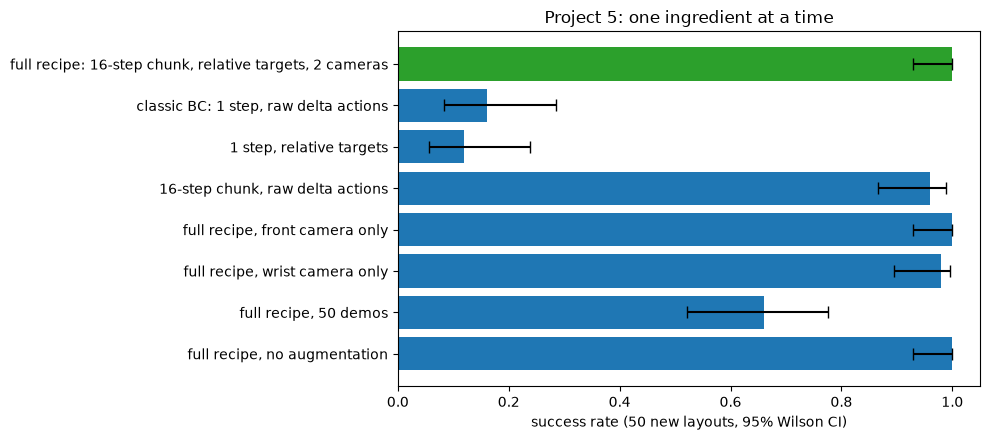

In [3]:
names = list(results)
s = np.array([results[n]["success"] for n in names]); lo = np.array([results[n]["ci"][0] for n in names]); hi = np.array([results[n]["ci"][1] for n in names])
plt.figure(figsize=(10, 4.5)); plt.barh(names, s, xerr=np.clip([s - lo, hi - s], 0, None), capsize=4, color=["tab:green"] + ["tab:blue"] * (len(names) - 1))
plt.xlim(0, 1.05); plt.xlabel("success rate (50 new layouts, 95% Wilson CI)"); plt.gca().invert_yaxis(); plt.title("Project 5: one ingredient at a time"); plt.tight_layout(); plt.show()

In [4]:
os.makedirs("results", exist_ok=True)
json.dump({n: dict(success=r["success"], ci=list(r["ci"]), per_task=r["per_task"]) for n, r in results.items()}, open("results/project5_pixel_bc.json", "w"), indent=1)
print("saved results/project5_pixel_bc.json  (S08 compares ACT / diffusion / flow against the 'full recipe' row)")

saved results/project5_pixel_bc.json  (S08 compares ACT / diffusion / flow against the 'full recipe' row)


### Watch the difference
Same table, same cube, same instruction: the full recipe vs the classic textbook recipe.

In [5]:
from vlacourse import showcase as sc
best, classic = names[0], names[1]
sc.compare(env, {"classic BC (1 step, raw deltas)": pols[classic], "full recipe": pols[best]},
           seed=sc.pick_seed(results[best], results[classic], 50_000), title="62 classic BC vs the full recipe")

62 classic BC vs the full recipe: classic BC (1 step, raw deltas): failed | full recipe: success


[False, True]